Modelagem preditiva do risco de insatisfação

Objetivo

Construir uma prova de conceito capaz de identificar clientes com risco de se tornarem detratores a partir de informações operacionais disponíveis durante a jornada.
O objetivo do modelo não é substituir os alertas operacionais identificados na análise exploratória, mas combinar diferentes sinais de risco e apoiar a priorização de clientes para atuação preventiva.
Como a base não possui informações temporais detalhadas sobre a jornada, o modelo será tratado como uma prova de conceito. Em uma aplicação real, somente informações disponíveis no momento da previsão poderiam ser utilizadas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

df = pd.read_csv(
    "../1.data/2.processed/desafio_nps_fase_1_processed.csv"
)

df.shape

(2500, 22)

Variável alvo

A variável alvo identifica clientes que apresentam risco de insatisfação:

1 = Detrator;
0 = Não detrator.
A classificação binária foi escolhida porque permite transformar o problema em uma decisão operacional: identificar clientes com maior risco de insatisfação antes da coleta do NPS.

In [2]:
# Dinifir variável alvo

df["target_detrator"] = (
    df["nps_score"] <= 6
).astype(int)

df["target_detrator"].value_counts(normalize=True)

target_detrator
1    0.7404
0    0.2596
Name: proportion, dtype: float64

Seleção das variáveis

Foram utilizadas características do cliente, pedido, logística e atendimento que poderiam representar sinais disponíveis durante a jornada.

Foram excluídos identificadores e todas as variáveis derivadas diretamente do NPS.

A variável repeat_purchase_30d foi excluída devido à relação determinística identificada com o NPS durante a EDA.

O csat_internal_score também foi excluído do modelo principal, pois não existem informações suficientes sobre sua construção e momento de disponibilidade, evitando possível vazamento de informação.

In [3]:
features = [
    "customer_age",
    "customer_region",
    "customer_tenure_months",
    "order_value",
    "items_quantity",
    "discount_value",
    "payment_installments",
    "delivery_time_days",
    "delivery_delay_days",
    "freight_value",
    "delivery_attempts",
    "customer_service_contacts",
    "resolution_time_days",
    "complaints_count"
]

X = df[features]
y = df["target_detrator"]

Separação dos dados

A base foi dividida em 80% para treinamento e 20% para teste.

Foi utilizada estratificação da variável alvo para manter proporções semelhantes de detratores nos dois conjuntos.

O conjunto de teste permanecerá fora do treinamento e será utilizado para avaliar o comportamento do modelo em clientes não utilizados durante seu ajuste.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("\nDistribuição treino:")
print(y_train.value_counts(normalize=True))

print("\nDistribuição teste:")
print(y_test.value_counts(normalize=True))

Treino: (2000, 14)
Teste: (500, 14)

Distribuição treino:
target_detrator
1    0.7405
0    0.2595
Name: proportion, dtype: float64

Distribuição teste:
target_detrator
1    0.74
0    0.26
Name: proportion, dtype: float64


In [6]:
# Usar StandardScaler principalmente porque a regressão logística trabalha melhor quando variáveis com escalas muito diferentes são padronizadas.

variaveis_categoricas = [
    "customer_region"
]

variaveis_numericas = [
    coluna
    for coluna in features
    if coluna not in variaveis_categoricas
]

preprocessor_lr = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            variaveis_numericas
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            variaveis_categoricas
        )
    ]
)

In [ ]:
# Modelo principal: Regressão Logística
# Preparação da estrutura

modelo_logistico = Pipeline(
    steps=[
        ("preprocessor", preprocessor_lr),
        (
            "modelo",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

modelo_logistico.fit(
    X_train,
    y_train
)

pred_lr = modelo_logistico.predict(X_test)

prob_lr = modelo_logistico.predict_proba(
    X_test
)[:, 1]

In [ ]:
# Exibição dos resultados de Avaliação
print(
    classification_report(
        y_test,
        pred_lr,
        target_names=[
            "Não detrator",
            "Detrator"
        ]
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            prob_lr
        ),
        3
    )
)

              precision    recall  f1-score   support

Não detrator       0.75      0.59      0.66       130
    Detrator       0.87      0.93      0.90       370

    accuracy                           0.84       500
   macro avg       0.81      0.76      0.78       500
weighted avg       0.84      0.84      0.84       500

ROC-AUC: 0.876


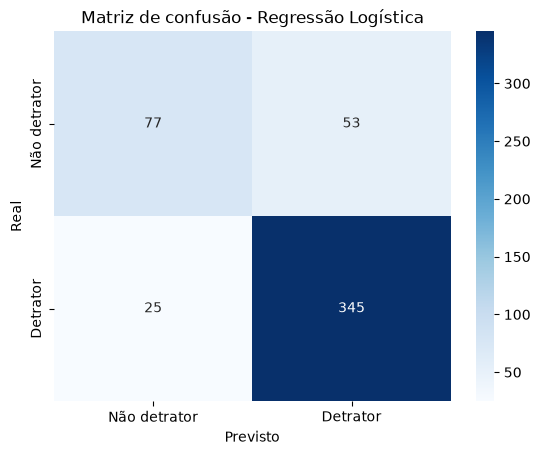

In [ ]:
# Montagem da Matriz de Confusão para visualizar eficácia do modelo
matriz_lr = confusion_matrix(
    y_test,
    pred_lr
)

sns.heatmap(
    matriz_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Não detrator",
        "Detrator"
    ],
    yticklabels=[
        "Não detrator",
        "Detrator"
    ]
)

plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de confusão - Regressão Logística")

plt.show()

In [ ]:
# Modelo comparativo: Random Forest
# PReparação da estrutura

preprocessor_rf = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            variaveis_categoricas
        )
    ],
    remainder="passthrough"
)

modelo_rf = Pipeline(
    steps=[
        ("preprocessor", preprocessor_rf),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

modelo_rf.fit(
    X_train,
    y_train
)

pred_rf = modelo_rf.predict(X_test)

prob_rf = modelo_rf.predict_proba(
    X_test
)[:, 1]

In [ ]:
# Exibição dos resultados de Avaliação

print(
    classification_report(
        y_test,
        pred_rf,
        target_names=[
            "Não detrator",
            "Detrator"
        ]
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            prob_rf
        ),
        3
    )
)

              precision    recall  f1-score   support

Não detrator       0.76      0.55      0.64       130
    Detrator       0.86      0.94      0.90       370

    accuracy                           0.84       500
   macro avg       0.81      0.75      0.77       500
weighted avg       0.83      0.84      0.83       500

ROC-AUC: 0.864


Comparação e escolha do modelo

Os dois modelos apresentaram bom desempenho na identificação de clientes detratores.

A Regressão Logística alcançou 84% de acurácia, recall de 93% para detratores, F1-score de 90% e ROC-AUC de 0,876. Entre os 370 detratores presentes no conjunto de teste, 345 foram corretamente identificados e 25 não foram detectados.

A Random Forest também apresentou 84% de acurácia e F1-score de 90% para detratores. Seu recall para a classe detratora foi ligeiramente superior, atingindo 94%, mas o ROC-AUC foi menor, com resultado de 0,864.

A Regressão Logística foi escolhida como modelo principal. A diferença de desempenho entre os modelos foi pequena, enquanto a Regressão Logística oferece maior simplicidade, interpretabilidade e facilidade de utilização das probabilidades em regras operacionais.

Como 74% da base pertence a classe detratora, a acurácia não foi utilizada isoladamente para avaliar os modelos. Foram priorizados o recall da classe detratora, o F1-score, a matriz de confusão e o ROC-AUC.

O modelo deve ser interpretado como uma prova de conceito. A base não possui o momento exato em que os eventos ocorreram e algumas variáveis representam o resultado completo da jornada. Para uma aplicação preventiva real, seria necessário utilizar apenas informações disponíveis no momento de cada previsão.